# Sharpness along trajectories

Quantitative companion to §4 of `well_walrus_dataset_categorisation.md`. We can look at 3 per-frame metrics to judge sharpness. All use forward cell differences $\Delta f$, after trimming 4 cells at every edge so walls and open boundaries do not affect anything:

- Front width ($w$): Take the field's $0.1^{st} \text{--} 99.96{th}$ percentile values to get a range. Then take once cell differences and take the $99.96{th}$ percentile difference. Then divide. Smaller values can mean shocks, larges can mean smooth.
- Gradient resolution ($R$): Take the differences Δf, then the differences of those, Δ²f. R = (size of Δ²f) / (size of Δf), with the sizes summed over the whole field. If Δ²f is as big as Δf, giving R = √2 ≈ 1.41, then this is ther maximum for a jump. R measures how well the grid resolves the field's gradients, averaged over the whole frame.
- Gradient sparsity (S): (average of |∇f|)² / (average of |∇f|²). If gradients are equal everywhere the ratio is 1. If gradients only in a fraction p of the cells, the ratio is about p. If 2% of cells carry all the change, S ≈ 0.02.

| Metric | Definition | Step (jump) | Sine, wavelength $\lambda$ cells | Reading |
|---|---|---|---|---|
| (w) front width | $(P_{99.9} - P_{0.1})\,/\,P_{99.9}(\lvert\Delta f\rvert)$, in cells | $\approx 1$ | $\approx \lambda/\pi$ | cells spanned by the steepest fronts; $\approx 1$ means a jump |
| (R) gradient resolution | $\lVert\Delta^2 f\rVert / \lVert\Delta f\rVert$ | $\sqrt2$ | $2\sin(\pi/\lambda)$ | bulk: how much the slope changes per cell; near $\sqrt2$ means under-resolved |
| (S) gradient sparsity | $\langle\lvert\nabla f\rvert\rangle^2 / \langle\lvert\nabla f\rvert^2\rangle$ | fraction of cells on the front | $\approx 0.81$ | where gradients live: concentration, not sharpness (replaces §4's flatness and top-1%) |

A shock shows small $w$, $R$ near $\sqrt2$ and small $S$. A steep, resolved filament shows small $S$ but $w$ of several cells and small $R$. A smooth field shows large $w$, small $R$ and large $S$. All three are in grid cells, which is what WALRUS's patch encoder sees.

§4.1 says sharpness belongs to each field, not each dataset (e.g. `viscoelastic_instability`: smooth velocity, sharp $C$). So each dataset is measured on its scalar from the diffusion notebook ($\log_{10}$ density for SN and TGC, whose heavy tails otherwise make single-cell jumps exceed the field's range) and on one velocity component ($x$-momentum for `euler_multi_quadrants`; no velocity in `gray_scott` or `helmholtz_staircase`). Sweeps use the scalar only. 8 trajectories per dataset and 5 per sweep value, 50 frames each, time as $t/T$. 3D datasets use the full volume.

In [1]:
import json, re
from pathlib import Path
import h5py, numpy as np, matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path("/leonardo_work/ICT26_MHPC_0/sshamsi/datasets")
CACHE = Path("sharpness_metrics.json")
N, K, KS = 50, 8, 5   # frames per trajectory, trajectories per dataset, trajectories per sweep value
TRIM = 4              # cells dropped at every edge
T = np.linspace(0, 1, N)

FIELD = {  # dataset -> (scalar field, component); same mapping as diffusion_trajectories.ipynb
    "shear_flow": ("t0_fields/tracer", ()),
    "rayleigh_benard": ("t0_fields/buoyancy", ()),
    "viscoelastic_instability": ("t2_fields/C", (0, 0)),   # C_xx
    "gray_scott_reaction_diffusion": ("t0_fields/A", ()),
    "active_matter": ("t0_fields/concentration", ()),
    "rayleigh_taylor_instability": ("t0_fields/density", ()),
    "planetswe": ("t0_fields/height", ()),
    "acoustic_scattering_discontinuous": ("t0_fields/pressure", ()),
    "acoustic_scattering_inclusions": ("t0_fields/pressure", ()),
    "acoustic_scattering_maze": ("t0_fields/pressure", ()),
    "helmholtz_staircase": ("t0_fields/pressure_re", ()),
    "euler_multi_quadrants_periodicBC": ("t0_fields/density", ()),
    "euler_multi_quadrants_openBC": ("t0_fields/density", ()),
    "turbulent_radiative_layer_2D": ("t0_fields/density", ()),
    "turbulent_radiative_layer_3D": ("t0_fields/density", ()),
    "MHD_64": ("t0_fields/density", ()),
    "supernova_explosion_128": ("t0_fields/density", ()),
    "turbulence_gravity_cooling": ("t0_fields/density", ()),
}
LOG = {"supernova_explosion_128", "turbulence_gravity_cooling"}  # scalar as log10 density: heavy tails make linear jumps exceed the range
VEL = {ds: ("t1_fields/momentum" if ds.startswith("euler") else "t1_fields/velocity", (0,))  # first component
       for ds in FIELD if ds not in ("gray_scott_reaction_diffusion", "helmholtz_staircase")}
DIFFUSIVE = list(FIELD)[:7]
NON_DIFFUSIVE = list(FIELD)[7:]
SWEEPS = {  # name -> (dataset, file globs covering every value on disk, regex for the swept value or None)
    "shear_flow Re (Sc=1)": ("shear_flow", ["*Schmidt_1e0.*"], r"Reynolds_([^_]+)"),
    "shear_flow Sc (Re=1e5)": ("shear_flow", ["*Reynolds_1e5_*"], r"Schmidt_([^_]+)$"),
    "rayleigh_benard Ra (Pr=1)": ("rayleigh_benard", ["*Prandtl_1.*"], r"Rayleigh_([^_]+)"),
    "TRL2D t_cool": ("turbulent_radiative_layer_2D", ["*.hdf5"], r"tcool_([^_]+)$"),
    "viscoelastic regime": ("viscoelastic_instability", ["*_AH.*", "*_CAR.*", "*_EIT.*"], None),
    "EMQ periodic gamma": ("euler_multi_quadrants_periodicBC", ["*.hdf5"], r"gamma_([^_]+)"),
    "MHD Ms (Ma=2)": ("MHD_64", ["*Ma_2_*"], r"Ms_([^_]+)$"),
    "TGC Z (rho0=4.45, T0=100)": ("turbulence_gravity_cooling", ["*rho0_4.45_*T0_100.*"], r"_Z_([^_]+)_"),
}


def sharp(a):
    """Front width w, gradient resolution R, gradient sparsity S of one frame (2D or 3D), edges trimmed."""
    a = np.ascontiguousarray(a[(slice(TRIM, -TRIM),) * a.ndim])  # component views are strided; np.diff on them is ~10x slower
    d = [np.diff(a, axis=k) for k in range(a.ndim)]          # float32; sums accumulate in float64
    d2 = [np.diff(a, 2, axis=k) for k in range(a.ndim)]
    lo, hi = np.percentile(a, [0.1, 99.9])  # same tails as the jump percentile; sparse features (initial rings) still count
    # ponytail: P99.9 from every 4th difference (>=~10^3 samples above it on our grids); use all if fronts are rarer than that
    w = (hi - lo) / np.percentile(np.abs(np.concatenate([x.ravel()[::4] for x in d])), 99.9)
    R = np.sqrt(sum(np.square(x).sum(dtype=np.float64) for x in d2) / sum(np.square(x).sum(dtype=np.float64) for x in d))
    g = np.sqrt(sum(np.square(x[tuple(slice(0, s - 1) for s in a.shape)]) for x in d))  # |grad f| on a common grid, float32
    return w, R, g.mean(dtype=np.float64) ** 2 / np.square(g).mean(dtype=np.float64)


def metrics(f, field, comp, traj, log=False):
    """(w, R, S) for N strided frames of one trajectory; one frame in memory at a time."""
    with h5py.File(f) as h:
        d = h[field]
        idx = np.unique(np.linspace(0, d.shape[1] - 1, N).astype(int))
        with np.errstate(divide="ignore", invalid="ignore"):  # a uniform frame gives inf/nan; plots skip them
            out = np.array([sharp(np.log10(x) if log else x) for x in (d[traj, i][(...,) + comp] for i in idx)])
    return {"t": (idx / idx[-1]).tolist(), **{m: out[:, j].tolist() for j, m in enumerate("wRS")}}


def files(ds, globs):
    return sorted({f for g in globs for f in (ROOT / ds / "data/train").glob(g)})


def subset(ds):
    """K (file, traj) pairs: files evenly spaced over the sorted list; with fewer than K files, extra trajectories."""
    fs = files(ds, ["*.hdf5"])
    sel = [fs[i] for i in np.linspace(0, len(fs) - 1, min(K, len(fs))).astype(int)]
    return [(sel[i % len(sel)], i // len(sel)) for i in range(K)]


def stack(ms, m):
    """Trajectories of metric m interpolated onto T -> (n_traj, N)."""
    return np.array([np.interp(T, x["t"], x[m]) for x in ms])


def value(name, stem):
    """(sort key, legend label) for one sweep file."""
    rx = SWEEPS[name][2]
    m = re.search(rx, stem) if rx else None
    return (float(m.group(1)), m.group(0).strip("_")) if m else (0, stem.rsplit("_", 1)[-1])


# self-check against the reference values in the table above; those are long-domain values, a 64-cell window is within a few %
x = np.arange(72, dtype=np.float32)
step = np.broadcast_to((x >= 36).astype(np.float32), (72, 72)).copy()
sine = np.broadcast_to(np.sin(2 * np.pi * x / 16), (72, 72)).astype(np.float32)
w, R, S = sharp(step); assert abs(w - 1) < 0.01 and abs(R - 2 ** 0.5) < 0.01 and S < 0.05, (w, R, S)
w, R, S = sharp(sine); assert abs(w - 16 / np.pi) < 0.3 and abs(R / (2 * np.sin(np.pi / 16)) - 1) < 0.05 and abs(S - 0.81) < 0.03, (w, R, S)

cache = json.loads(CACHE.read_text()) if CACHE.exists() else {}

## Compute

Two fields per dataset, 8 trajectories each, plus the scalar for every sweep value, 5 trajectories each. Resumable: keys already in `sharpness_metrics.json` with the same number of trajectories are skipped.

In [2]:
tasks = [(f"{ds}:scalar", FIELD[ds], ds in LOG, subset(ds)) for ds in FIELD] + \
        [(f"{ds}:velocity", VEL[ds], False, subset(ds)) for ds in VEL] + [
        (f"{name}|{f.stem}", FIELD[ds], ds in LOG, [(f, t) for t in range(KS)])
        for name, (ds, globs, _) in SWEEPS.items() for f in files(ds, globs)]
for key, (field, comp), log, pairs in tasks:
    if len(cache.get(key, [])) == len(pairs): continue
    cache[key] = [metrics(f, field, comp, t, log) for f, t in pairs]
    CACHE.write_text(json.dumps(cache))
    print("done", key)

done shear_flow:scalar
done rayleigh_benard:scalar
done viscoelastic_instability:scalar
done gray_scott_reaction_diffusion:scalar
done active_matter:scalar
done rayleigh_taylor_instability:scalar
done planetswe:scalar
done acoustic_scattering_discontinuous:scalar
done acoustic_scattering_inclusions:scalar
done acoustic_scattering_maze:scalar
done helmholtz_staircase:scalar
done euler_multi_quadrants_periodicBC:scalar
done euler_multi_quadrants_openBC:scalar
done turbulent_radiative_layer_2D:scalar
done turbulent_radiative_layer_3D:scalar
done MHD_64:scalar
done supernova_explosion_128:scalar
done turbulence_gravity_cooling:scalar
done shear_flow:velocity
done rayleigh_benard:velocity
done viscoelastic_instability:velocity
done active_matter:velocity
done rayleigh_taylor_instability:velocity
done planetswe:velocity
done acoustic_scattering_discontinuous:velocity
done acoustic_scattering_inclusions:velocity
done acoustic_scattering_maze:velocity
done euler_multi_quadrants_periodicBC:velo

## 1. All datasets, one panel per metric

Median over the 8 trajectories. Blue: diffusive (§3), red: non-diffusive. Dashed guides: $w = 1$ and $R = \sqrt2$ mark a one-cell jump. Top row: the scalar field. Bottom row: velocity. Expect shocks (EMQ, SN, supersonic MHD) near the guides, and diffusive scalars with large $w$ and small $R$.

/scratch_local/ipykernel_1086034/3009576863.py:7: RuntimeWarning: All-NaN slice encountered
  ax.plot(T, np.nanmedian(stack(cache[f"{ds}:{tag}"], m), 0), color=cmap(0.35 + 0.65 * i / len(group)), label=ds)


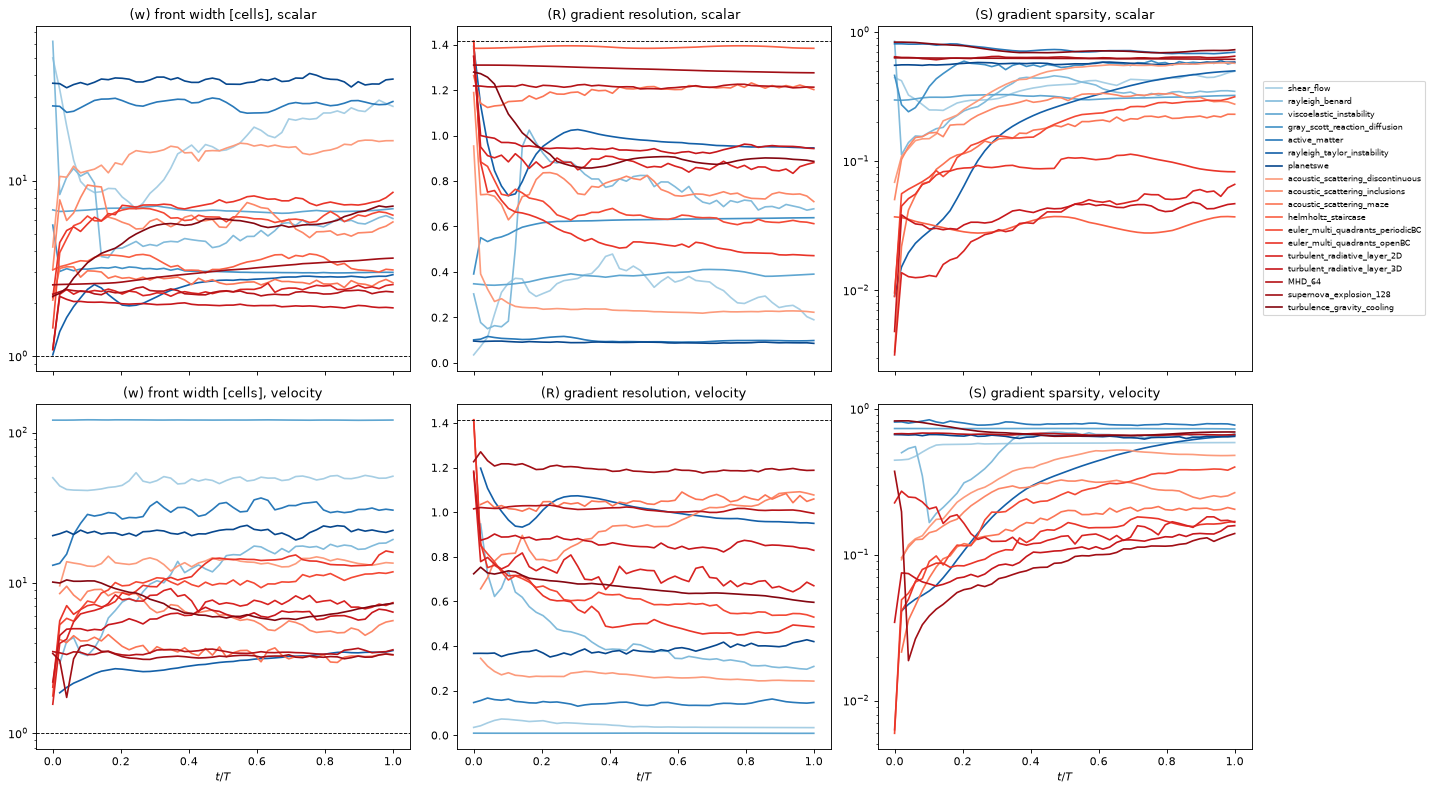

In [3]:
fig, axs = plt.subplots(2, 3, figsize=(18, 10), dpi=80, sharex=True)
for row, tag in enumerate(("scalar", "velocity")):
    for group, cmap in ((DIFFUSIVE, plt.cm.Blues), (NON_DIFFUSIVE, plt.cm.Reds)):
        for i, ds in enumerate(group):
            if f"{ds}:{tag}" not in cache: continue
            for ax, m in zip(axs[row], "wRS"):
                ax.plot(T, np.nanmedian(stack(cache[f"{ds}:{tag}"], m), 0), color=cmap(0.35 + 0.65 * i / len(group)), label=ds)
    for ax, title in zip(axs[row], ["(w) front width [cells]", "(R) gradient resolution", "(S) gradient sparsity"]):
        ax.set_title(f"{title}, {tag}")
    axs[row, 0].set_yscale("log"); axs[row, 0].axhline(1, ls="--", c="k", lw=0.8)
    axs[row, 1].axhline(2 ** 0.5, ls="--", c="k", lw=0.8); axs[row, 2].set_yscale("log")
for ax in axs[1]: ax.set_xlabel("$t/T$")
axs[0, 2].legend(fontsize=7, loc="center left", bbox_to_anchor=(1.02, 0.5))
fig.tight_layout(); display(fig); plt.close(fig)

## 2. Per dataset: scalar vs velocity

Front width $w$, median with the 25–75% band over the 8 trajectories. Solid: scalar; dashed: velocity. A gap between the two lines is §4.1's "sharpness belongs to the field": e.g. `viscoelastic_instability`, with sharp $C_{xx}$ and smooth velocity.

/leonardo_work/ICT26_MHPC_0/sshamsi/pyenvs/env1/lib/python3.11/site-packages/numpy/lib/nanfunctions.py:1563: RuntimeWarning: All-NaN slice encountered
  return function_base._ureduce(a,


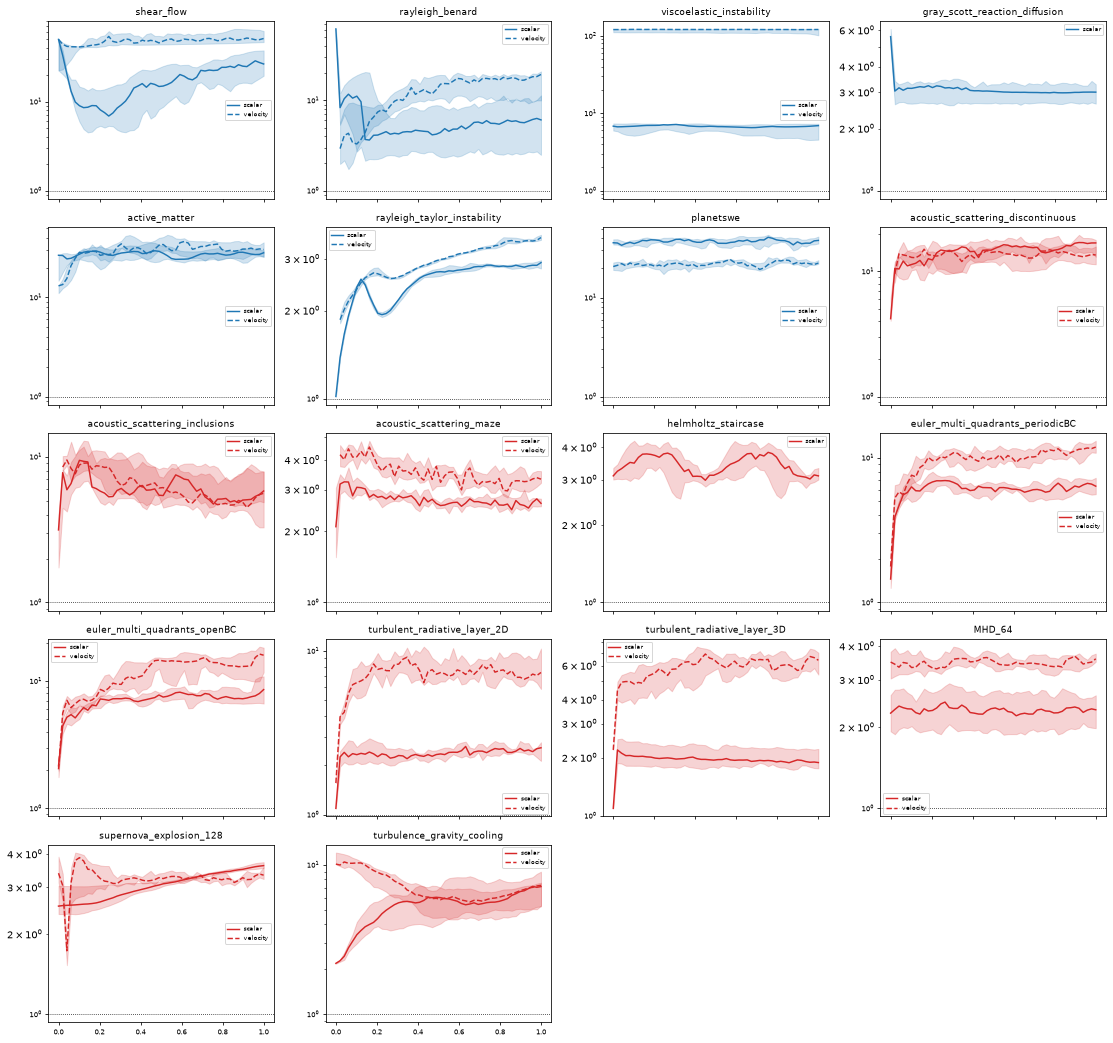

In [4]:
fig, axs = plt.subplots(5, 4, figsize=(16, 15), dpi=70, sharex=True)
for ax, ds in zip(axs.flat, FIELD):
    c = "tab:blue" if ds in DIFFUSIVE else "tab:red"
    for tag, ls in (("scalar", "-"), ("velocity", "--")):
        if f"{ds}:{tag}" not in cache: continue
        q = np.nanpercentile(stack(cache[f"{ds}:{tag}"], "w"), [25, 50, 75], axis=0)
        ax.fill_between(T, q[0], q[2], color=c, alpha=0.2); ax.plot(T, q[1], color=c, ls=ls, label=tag)
    ax.set_yscale("log"); ax.axhline(1, ls=":", c="k", lw=0.8)
    ax.set_title(ds, fontsize=9); ax.tick_params(labelsize=7); ax.legend(fontsize=6)
for ax in axs.flat[len(FIELD):]: ax.axis("off")
fig.tight_layout(); display(fig); plt.close(fig)

### 2b. Examples: diffusive

GIFs from `diffusion_trajectories.ipynb` (its Render cell writes `gifs/`): trajectory 0 of the first and last file. Look for whether fronts span one cell or several.

#### `shear_flow`

Thin tracer filaments, but each spans several cells: resolved, not shocks.

![shear_flow](gifs/shear_flow.gif)

#### `rayleigh_benard`

Plume edges thin as $Ra$ rises, but stay smooth across cells.

![rayleigh_benard](gifs/rayleigh_benard.gif)

#### `viscoelastic_instability`

Thin $C_{xx}$ sheets: steep-but-resolved, the 'borderline' case of §4.1.

![viscoelastic_instability](gifs/viscoelastic_instability.gif)

#### `gray_scott_reaction_diffusion`

Reaction fronts of fixed finite width, set by diffusion.

![gray_scott_reaction_diffusion](gifs/gray_scott_reaction_diffusion.gif)

#### `active_matter`

Smooth concentration bands; no fronts.

![active_matter](gifs/active_matter.gif)

#### `rayleigh_taylor_instability`

Mixing-zone interfaces, smoothed by molecular diffusion.

![rayleigh_taylor_instability](gifs/rayleigh_taylor_instability.gif)

#### `planetswe`

Large smooth systems; no hydraulic jumps form.

![planetswe](gifs/planetswe.gif)

### 2c. Examples: non-diffusive

#### `acoustic_scattering_discontinuous`

Kinks where wavefronts cross the density interface; the fronts themselves are smooth.

![acoustic_scattering_discontinuous](gifs/acoustic_scattering_discontinuous.gif)

#### `acoustic_scattering_inclusions`

Many reflections off inclusions; sharp at the inclusion edges.

![acoustic_scattering_inclusions](gifs/acoustic_scattering_inclusions.gif)

#### `acoustic_scattering_maze`

Waves confined by maze walls; sharp only at the walls.

![acoustic_scattering_maze](gifs/acoustic_scattering_maze.gif)

#### `helmholtz_staircase`

Smooth time-harmonic field; singular only at the staircase corners.

![helmholtz_staircase](gifs/helmholtz_staircase.gif)

#### `euler_multi_quadrants_periodicBC`

Shocks and contact discontinuities: one-cell jumps.

![euler_multi_quadrants_periodicBC](gifs/euler_multi_quadrants_periodicBC.gif)

#### `euler_multi_quadrants_openBC`

Same shocks; waves leave through the boundaries.

![euler_multi_quadrants_openBC](gifs/euler_multi_quadrants_openBC.gif)

#### `turbulent_radiative_layer_2D`

Sharp hot/cold interfaces kept thin by cooling.

![turbulent_radiative_layer_2D](gifs/turbulent_radiative_layer_2D.gif)

#### `turbulent_radiative_layer_3D`

The same interfaces in 3D (mid-plane).

![turbulent_radiative_layer_3D](gifs/turbulent_radiative_layer_3D.gif)

#### `MHD_64`

Subsonic file smooth; $M_s = 7$ file has shock-compressed filaments.

![MHD_64](gifs/MHD_64.gif)

#### `supernova_explosion_128`

A sharp blast shell ($\log_{10}$ density, as in the metrics).

![supernova_explosion_128](gifs/supernova_explosion_128.gif)

#### `turbulence_gravity_cooling`

Dense filaments steepening under collapse ($\log_{10}$ density, as in the metrics).

![turbulence_gravity_cooling](gifs/turbulence_gravity_cooling.gif)

## 3. Parameter sweeps (scalar field)

One curve per value of the swept parameter (others fixed), median of 5 trajectories. Expect higher $Re$, $Sc$ or $Ra$ to give smaller $w$ (thinner fronts) without reaching one cell, higher $M_s$ to push MHD towards shocks, and shorter $t_{\rm cool}$ to thin the TRL interfaces.

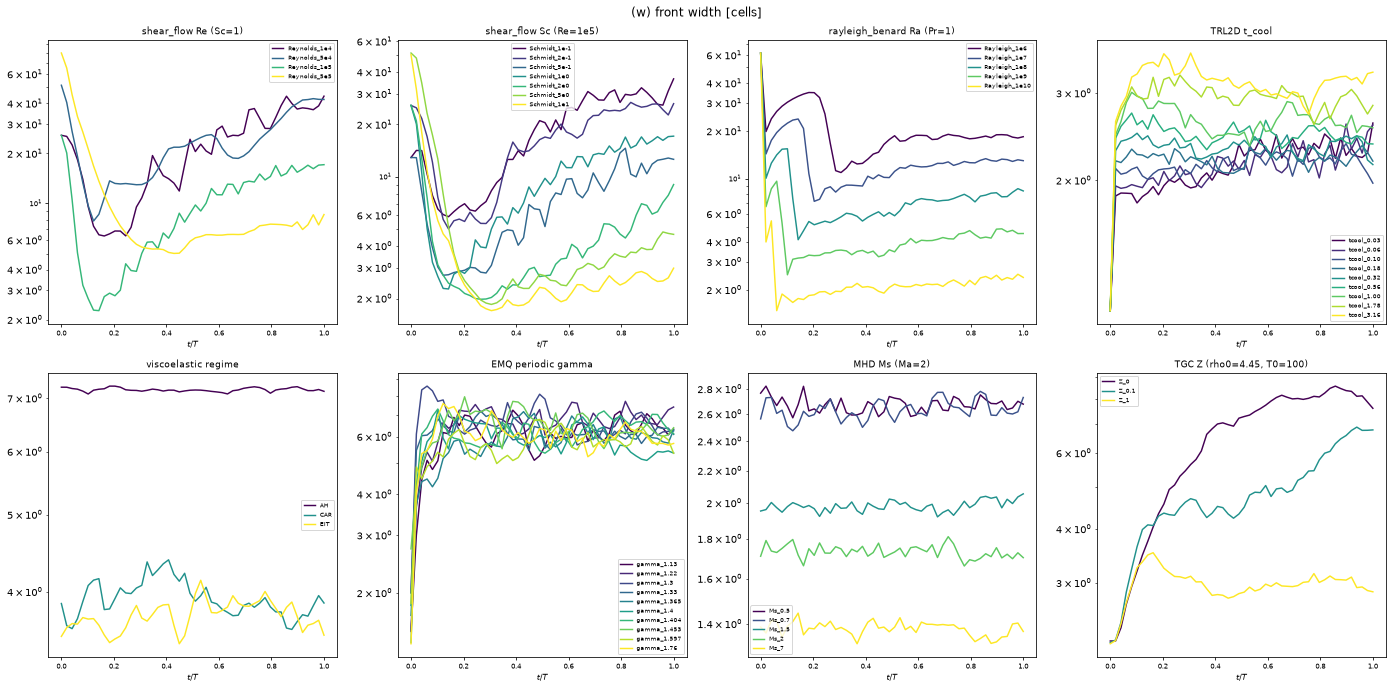

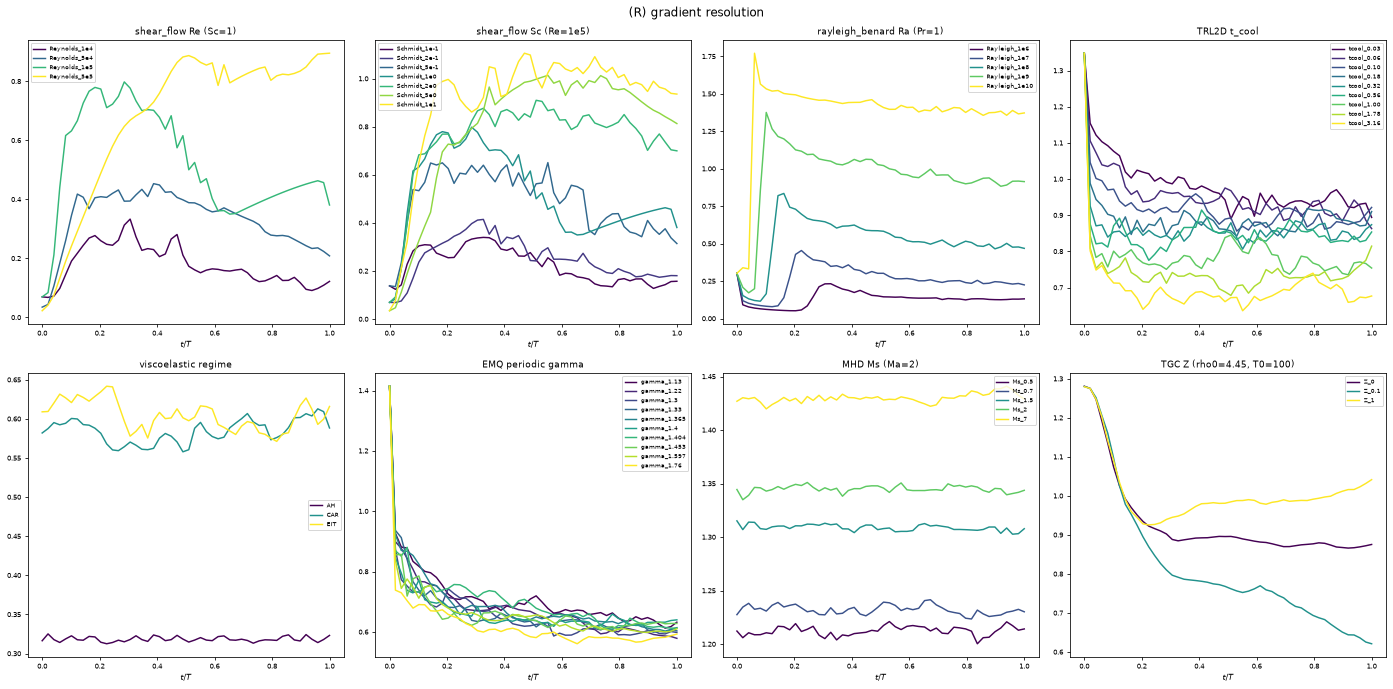

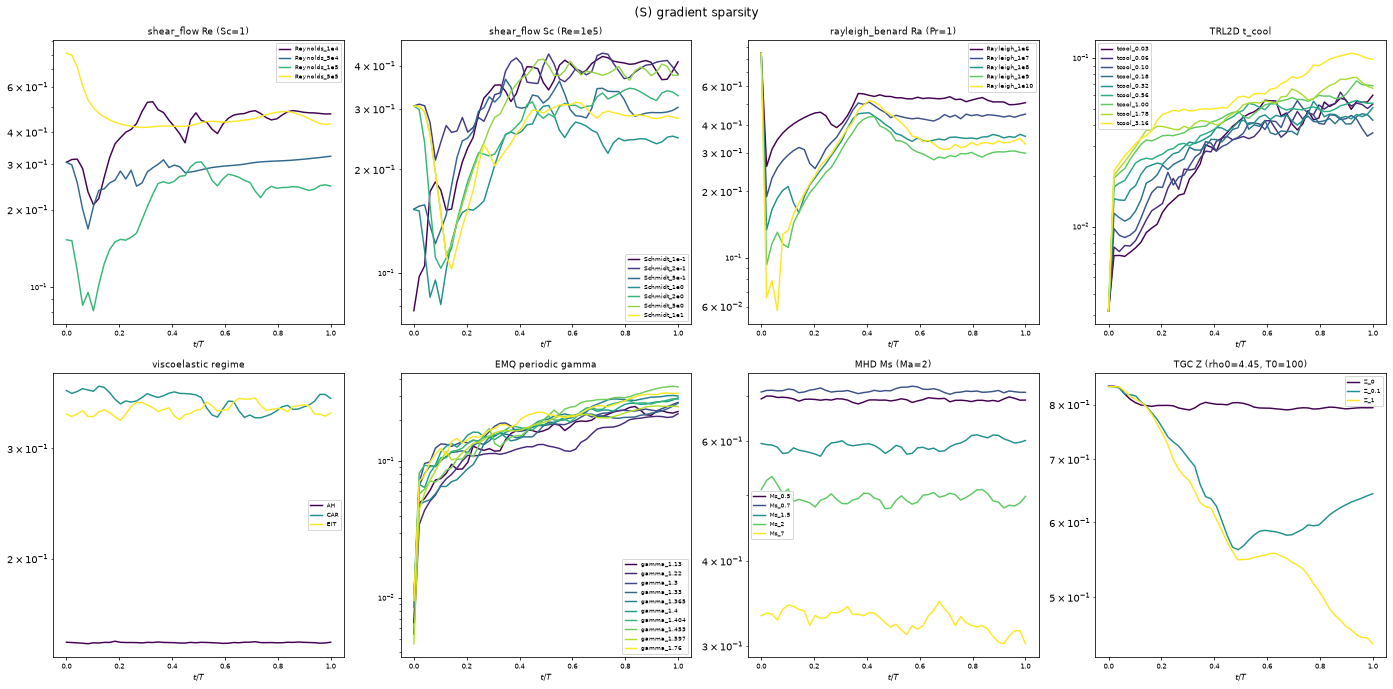

In [5]:
for m, title, log in (("w", "(w) front width [cells]", True), ("R", "(R) gradient resolution", False), ("S", "(S) gradient sparsity", True)):
    fig, axs = plt.subplots(2, 4, figsize=(20, 10), dpi=70)
    for ax, name in zip(axs.flat, SWEEPS):
        keys = sorted((k for k in cache if k.startswith(name + "|")), key=lambda k: value(name, k.split("|")[1])[0])
        for i, k in enumerate(keys):
            ax.plot(T, np.nanmedian(stack(cache[k], m), 0), color=plt.cm.viridis(i / max(len(keys) - 1, 1)),
                    label=value(name, k.split("|")[1])[1])
        ax.set_yscale("log" if log else "linear"); ax.set_title(name, fontsize=9); ax.set_xlabel("$t/T$", fontsize=8)
        ax.legend(fontsize=6); ax.tick_params(labelsize=7)
    fig.suptitle(title); fig.tight_layout(); display(fig); plt.close(fig)

### 3b. Sweep examples

Lowest, middle and highest value of each sweep (trajectory 0), from `gifs/`.

#### shear_flow Re (Sc=1)

![shear_flow Re (Sc=1)](gifs/shear_flow_Re_Sc_1.gif)

#### shear_flow Sc (Re=1e5)

![shear_flow Sc (Re=1e5)](gifs/shear_flow_Sc_Re_1e5.gif)

#### rayleigh_benard Ra (Pr=1)

![rayleigh_benard Ra (Pr=1)](gifs/rayleigh_benard_Ra_Pr_1.gif)

#### TRL2D t_cool

![TRL2D t_cool](gifs/TRL2D_t_cool.gif)

#### viscoelastic regime

![viscoelastic regime](gifs/viscoelastic_regime.gif)

#### EMQ periodic gamma

![EMQ periodic gamma](gifs/EMQ_periodic_gamma.gif)

#### MHD Ms (Ma=2)

![MHD Ms (Ma=2)](gifs/MHD_Ms_Ma_2.gif)

#### TGC Z (rho0=4.45, T0=100)

![TGC Z (rho0=4.45, T0=100)](gifs/TGC_Z_rho0_4_45_T0_100.gif)